# Notebook 07 (V2) — Extração de features no PulseDB AAMI Test

**Projeto de Iniciação Científica PIBIC — PUC-SP**
**Aluna:** Letícia Barboza de Godoi
**Orientador:** Prof. Dr. Renan Trevisoli Doria
**Curso:** Engenharia Biomédica

---

## ⚠️ Nota sobre esta versão (V2)

A primeira versão deste notebook utilizou uma implementação da função `extrair_features_ciclo` que divergia sutilmente do código original `extract_pulse_features_v2` do NB02. As diferenças resultaram em:

- **55,5% dos ciclos com NaN** nas features `w*_ratio` (proporção fora do esperado);
- **`sut_dt_ratio` médio 120× maior** que o do PTT-PPG;
- Distribuições de larguras `sys` e `dia` significativamente distintas das do dataset original.

Esta segunda versão **reescreve a função de extração para replicar com fidelidade o algoritmo do NB02**, preservando inclusive os limites empíricos de qualidade (`n < 0.33*fs`, `dt > 0.02`, `sw > 0.005`). Após a correção, as distribuições das features invariantes devem ser comparáveis entre os dois datasets, validando a aplicabilidade da Versão C do modelo (35 features invariantes) ao PulseDB.

## Contexto

Este notebook aplica ao PulseDB AAMI Test o mesmo pipeline de extração de features morfológicas que foi desenvolvido para o PhysioNet PTT-PPG nos Notebooks 01 e 02. O objetivo é produzir um conjunto de dados estruturalmente idêntico ao `features_v2_clean.csv`, contendo as 41 features morfológicas calculadas por ciclo cardíaco em cada segmento do PulseDB.

## Diferenças metodológicas em relação ao PTT-PPG

| Aspecto | PTT-PPG | PulseDB AAMI Test |
|---|---|---|
| Frequência de amostragem | 500 Hz | **125 Hz** |
| Unidade de origem | Record contínuo (~10 min) | Segmento de 10 s (1.250 amostras) |
| Granularidade da feature | Por ciclo cardíaco | **Por ciclo cardíaco (mesma)** |
| Referência de PA | Por janela ao redor do ciclo | **SBP/DBP única por segmento** |
| Total de segmentos/registros | 66 records | 666 segmentos |

A diferença mais importante é a referência de pressão arterial: enquanto o PTT-PPG fornece um par SBP/DBP independente para cada janela, o PulseDB fornece uma única medida de SBP e DBP por segmento de 10 segundos. Todos os ciclos cardíacos extraídos do mesmo segmento receberão a mesma PA de referência.

## Features extraídas

Replicam-se exatamente as **41 features morfológicas** do NB02 (todas exceto `ptt_s` e `ptt_ms`, que dependem de ECG sincronizado). A seleção das 35 features da Versão C será feita no NB08.

---


## 1. Importações e configuração global

In [1]:
import os
import socket
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import mat73
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import skew, kurtosis

warnings.filterwarnings("ignore")
np.random.seed(42)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.dpi"] = 100

print("Computador:", socket.gethostname())
print("Inicio:", datetime.now().strftime("%d/%m/%Y %H:%M:%S"))
print("Bibliotecas carregadas.")

Computador: NtebookLeticia
Inicio: 09/06/2026 15:29:17
Bibliotecas carregadas.


In [2]:
# Caminhos
BASE_IC      = Path(r"C:\IC_PPG")
PASTA_DADOS  = BASE_IC / "data" / "ptt_ppg"
PASTA_PULSEDB = BASE_IC / "data" / "pulsedb_kaggle" / "datasets" / \
                "weinanwangrutgers" / "pulsedb-balanced-training-and-testing" / \
                "versions" / "4"
PASTA_FIGS = BASE_IC / "figures"

PASTA_PULSEDB_OUT = BASE_IC / "data" / "pulsedb_features"
PASTA_PULSEDB_OUT.mkdir(parents=True, exist_ok=True)

arquivo_aami = PASTA_PULSEDB / "VitalDB_AAMI_Test_Subset.mat"
if not arquivo_aami.exists():
    raise FileNotFoundError(f"Arquivo nao encontrado: {arquivo_aami}")

print(f"Arquivo de entrada: {arquivo_aami.name}")
print(f"Tamanho: {arquivo_aami.stat().st_size / (1024**2):.2f} MB")
print(f"Saida das features em: {PASTA_PULSEDB_OUT}")

Arquivo de entrada: VitalDB_AAMI_Test_Subset.mat
Tamanho: 18.89 MB
Saida das features em: C:\IC_PPG\data\pulsedb_features


## 2. Parâmetros do pipeline

Mantêm-se exatamente os mesmos parâmetros do NB01+02, com a única diferença sendo a frequência de amostragem.


In [3]:
# Parametros
FS = 125
DURACAO_SEGMENTO = 10
N_AMOSTRAS = FS * DURACAO_SEGMENTO

# Filtro Butterworth
FREQ_CORTE_INF = 0.5
FREQ_CORTE_SUP = 8.0
ORDEM_FILTRO   = 4

# Deteccao de picos
FC_MINIMA_BPM = 40
FC_MAXIMA_BPM = 200
DISTANCIA_MINIMA_S = 60.0 / FC_MAXIMA_BPM
DISTANCIA_MINIMA_AMOSTRAS = int(DISTANCIA_MINIMA_S * FS)

# Larguras de pulso
NIVEIS_LARGURA = [10, 25, 33, 50, 66, 75]

print(f"FS = {FS} Hz")
print(f"Filtro: ordem {ORDEM_FILTRO}, banda {FREQ_CORTE_INF}-{FREQ_CORTE_SUP} Hz")
print(f"Distancia minima entre picos: {DISTANCIA_MINIMA_AMOSTRAS} amostras")

FS = 125 Hz
Filtro: ordem 4, banda 0.5-8.0 Hz
Distancia minima entre picos: 37 amostras


## 3. Funções de processamento

### 3.1 Filtragem e detecção de picos


In [4]:
def projetar_filtro_butterworth(fs, freq_inf, freq_sup, ordem):
    """Projeta filtro Butterworth passa-banda."""
    nyquist = fs / 2.0
    return butter(ordem, [freq_inf/nyquist, freq_sup/nyquist], btype="band")


def aplicar_filtro_bidirecional(sinal, b, a):
    """Aplica filtfilt para preservar fase."""
    return filtfilt(b, a, sinal)


def detectar_picos_sistolicos(ppg_filtrado, distancia_minima):
    """find_peaks com altura adaptativa."""
    altura_min = np.median(ppg_filtrado) + 0.3 * (
        np.max(ppg_filtrado) - np.median(ppg_filtrado)
    )
    indices, _ = find_peaks(
        ppg_filtrado,
        distance=distancia_minima,
        height=altura_min,
    )
    return indices


coef_b, coef_a = projetar_filtro_butterworth(
    FS, FREQ_CORTE_INF, FREQ_CORTE_SUP, ORDEM_FILTRO
)
print("Funcoes de filtragem e deteccao prontas.")

Funcoes de filtragem e deteccao prontas.


### 3.2 Extração das 41 features morfológicas

Esta função é uma **reescrita em português, fiel ao algoritmo original** do `extract_pulse_features_v2` do NB02. Foram preservadas todas as proteções contra divisão por zero e os limites empíricos validados naquele notebook.


In [5]:
def extrair_features_ciclo(ppg_segmento, fs):
    """
    Extrai 41 features morfologicas de um unico ciclo cardiaco PPG.

    Esta funcao replica fielmente o algoritmo extract_pulse_features_v2
    desenvolvido no NB02 do projeto, com a versao final aprovada na
    avaliacao do relatorio parcial.

    Parametros
    ----------
    ppg_segmento : np.ndarray
        Ciclo PPG entre dois picos sistolicos consecutivos.
        Amplitude original (nao normalizada).
    fs : float
        Frequencia de amostragem em Hz.

    Retorna
    -------
    dict com 41 features OU None se o ciclo for invalido.

    Notas sobre as protecoes (idênticas ao NB02)
    --------------------------------------------
    - Ciclos com duracao < 0.33*fs OU > 2.0 s sao descartados.
    - Ciclos com amplitude < 1e-10 sao descartados.
    - Razao SUT/DT vira NaN se DT < 0.02 s (20 ms).
    - Razao w{pct}_ratio vira NaN se largura sistolica < 0.005 s (5 ms).
    """
    n = len(ppg_segmento)
    duracao_s = n / fs

    # Filtros de qualidade: ciclo muito curto ou muito longo
    if n < int(0.33 * fs) or duracao_s > 2.0:
        return None

    # Calculo da escala
    seg_min   = ppg_segmento.min()
    seg_max   = ppg_segmento.max()
    seg_range = seg_max - seg_min

    if seg_range < 1e-10:
        return None  # ciclo plano, sem informacao

    # Normalizacao min-max para features de forma
    seg_norm = (ppg_segmento - seg_min) / seg_range

    feats = {}

    # ===== TEMPORAIS =====
    feats["cardiac_period_s"] = duracao_s
    feats["heart_rate_bpm"]   = 60.0 / duracao_s

    # Indice do pico no ciclo normalizado
    peak_idx = int(np.argmax(seg_norm))
    sut = peak_idx / fs                # tempo de subida sistolica
    dt  = (n - peak_idx) / fs          # tempo diastolico

    feats["systolic_upstroke_time_s"] = sut
    feats["diastolic_time_s"]         = dt
    feats["sut_dt_ratio"] = sut / dt if dt > 0.02 else np.nan

    # ===== LARGURAS DE PULSO =====
    for pct in NIVEIS_LARGURA:
        threshold = pct / 100.0
        above = seg_norm >= threshold

        if above.sum() > 0:
            indices = np.where(above)[0]
            total_w = (indices[-1] - indices[0]) / fs

            # Larguras DENTRO de cada regiao (formula do NB02)
            sys_idx = indices[indices <= peak_idx]
            dia_idx = indices[indices >  peak_idx]

            sw = (sys_idx[-1] - sys_idx[0]) / fs if len(sys_idx) > 1 else 0.0
            dw = (dia_idx[-1] - dia_idx[0]) / fs if len(dia_idx) > 1 else 0.0

            feats[f"w{pct}_total"] = total_w
            feats[f"w{pct}_sys"]   = sw
            feats[f"w{pct}_dia"]   = dw
            feats[f"w{pct}_ratio"] = dw / sw if sw > 0.005 else np.nan
        else:
            feats[f"w{pct}_total"] = 0.0
            feats[f"w{pct}_sys"]   = 0.0
            feats[f"w{pct}_dia"]   = 0.0
            feats[f"w{pct}_ratio"] = np.nan

    # ===== AMPLITUDE (no ciclo BRUTO) =====
    feats["amplitude"]    = float(seg_max - seg_min)
    feats["peak_value"]   = float(seg_max)
    feats["valley_value"] = float(seg_min)
    if abs(seg_min) > 1e-9:
        feats["crest_factor"] = float(seg_max / abs(seg_min))
    else:
        feats["crest_factor"] = float(seg_max / 1e-9)

    # ===== ESTATISTICAS =====
    feats["variance"] = float(np.var(ppg_segmento))   # escala-dependente
    feats["std"]      = float(np.std(ppg_segmento))   # escala-dependente

    # skewness e kurtosis no ciclo normalizado (invariantes)
    feats["skewness"] = float(skew(seg_norm))
    feats["kurtosis"] = float(kurtosis(seg_norm, fisher=True))

    # AUC no ciclo normalizado (invariante)
    feats["auc"] = float(np.trapz(seg_norm) / fs)

    # ===== HJORTH =====
    activity = float(np.var(ppg_segmento))
    diff1 = np.diff(ppg_segmento)
    diff2 = np.diff(diff1)

    if activity > 1e-12:
        mobility = float(np.sqrt(np.var(diff1) / activity))
    else:
        mobility = np.nan

    var_d1 = float(np.var(diff1))
    if var_d1 > 1e-12 and not np.isnan(mobility) and mobility > 1e-12:
        complexity = float(
            (np.sqrt(np.var(diff2) / var_d1)) / mobility
        )
    else:
        complexity = np.nan

    feats["hjorth_activity"]   = activity
    feats["hjorth_mobility"]   = mobility
    feats["hjorth_complexity"] = complexity

    return feats


# Validacao rapida com sinal sintetico
sinal_teste = (np.sin(np.linspace(0, np.pi, 60)) ** 2)  # ciclo PPG aproximado
feats_teste = extrair_features_ciclo(sinal_teste, 60)

print(f"Teste: {len(feats_teste)} features extraidas (esperado: 41)")
assert len(feats_teste) == 41
print(f"sut_dt_ratio teste: {feats_teste['sut_dt_ratio']:.3f} (esperado ~1.0 - sinal simetrico)")
print(f"w50_ratio teste:    {feats_teste['w50_ratio']:.3f}")
print("Funcao validada.")

Teste: 41 features extraidas (esperado: 41)
sut_dt_ratio teste: 0.935 (esperado ~1.0 - sinal simetrico)
w50_ratio teste:    1.000
Funcao validada.


## 4. Processamento dos 666 segmentos do PulseDB

Aplica o pipeline completo (filtragem → detecção de picos → extração de features ciclo-a-ciclo) em todos os segmentos do AAMI Test.


In [6]:
# Carrega o subset
print("Carregando VitalDB_AAMI_Test_Subset.mat...")
dados = mat73.loadmat(str(arquivo_aami))
subset = dados["Subset"]

n_segmentos = subset["Signals"].shape[0]
print(f"Total de segmentos: {n_segmentos}")
print(f"Shape do array Signals: {subset['Signals'].shape}")

Carregando VitalDB_AAMI_Test_Subset.mat...
Total de segmentos: 666
Shape do array Signals: (666, 3, 1250)


In [7]:
print(f"Iniciando extracao em {n_segmentos} segmentos...")
print(f"Tempo estimado: ~10 segundos (segmentos curtos, computacao leve)")
print()
inicio = datetime.now()

linhas_features = []
problemas = {"sem_picos": 0, "ciclo_invalido": 0}

for idx_seg in range(n_segmentos):
    ppg_bruto = subset["Signals"][idx_seg, 1, :]
    ppg_filt  = aplicar_filtro_bidirecional(ppg_bruto, coef_b, coef_a)
    indices_picos = detectar_picos_sistolicos(ppg_filt, DISTANCIA_MINIMA_AMOSTRAS)

    if len(indices_picos) < 2:
        problemas["sem_picos"] += 1
        continue

    # Metadados do segmento
    sbp_seg = float(subset["SBP"][idx_seg])
    dbp_seg = float(subset["DBP"][idx_seg])

    sub_raw = subset["Subject"][idx_seg]
    if isinstance(sub_raw, list) and len(sub_raw) > 0:
        subject_id = f"v{sub_raw[0]}"
    else:
        subject_id = f"v{sub_raw}"

    idade  = float(subset["Age"][idx_seg])
    altura = float(subset["Height"][idx_seg])
    peso   = float(subset["Weight"][idx_seg])

    gen_raw = subset["Gender"][idx_seg]
    if isinstance(gen_raw, list) and len(gen_raw) > 0:
        genero = str(gen_raw[0])
    else:
        genero = str(gen_raw)

    # Itera entre picos consecutivos extraindo features
    for i in range(len(indices_picos) - 1):
        ini = indices_picos[i]
        fim = indices_picos[i+1]
        ciclo = ppg_filt[ini:fim]

        feats = extrair_features_ciclo(ciclo, FS)
        if feats is None:
            problemas["ciclo_invalido"] += 1
            continue

        # Metadados
        feats["record"]      = f"seg_{idx_seg:04d}"
        feats["subject"]     = subject_id
        feats["condition"]   = "rest"
        feats["cycle_idx"]   = i
        feats["peak_sample"] = int(ini)
        feats["time_s"]      = float(ini / FS)
        feats["bp_sys_start"] = sbp_seg
        feats["bp_sys_end"]   = sbp_seg
        feats["bp_dia_start"] = dbp_seg
        feats["bp_dia_end"]   = dbp_seg
        feats["bp_sys_mean"]  = sbp_seg
        feats["bp_dia_mean"]  = dbp_seg
        feats["age"]    = idade
        feats["gender"] = genero
        feats["height"] = altura
        feats["weight"] = peso

        linhas_features.append(feats)

    if (idx_seg + 1) % 100 == 0:
        decorrido = (datetime.now() - inicio).total_seconds()
        print(f"  {idx_seg+1}/{n_segmentos} segmentos | "
              f"{len(linhas_features)} ciclos | {decorrido:.0f} s")

duracao = (datetime.now() - inicio).total_seconds()
print()
print("=" * 60)
print(f"Extracao concluida em {duracao:.1f} s ({duracao/60:.2f} min)")
print(f"Ciclos extraidos:     {len(linhas_features)}")
print(f"Problemas:")
print(f"  Segmentos sem picos (< 2): {problemas['sem_picos']}")
print(f"  Ciclos invalidos:           {problemas['ciclo_invalido']}")

Iniciando extracao em 666 segmentos...
Tempo estimado: ~10 segundos (segmentos curtos, computacao leve)

  100/666 segmentos | 1080 ciclos | 3 s
  200/666 segmentos | 2263 ciclos | 6 s
  300/666 segmentos | 3502 ciclos | 9 s
  400/666 segmentos | 4641 ciclos | 12 s
  500/666 segmentos | 5816 ciclos | 15 s
  600/666 segmentos | 6948 ciclos | 18 s

Extracao concluida em 19.5 s (0.33 min)
Ciclos extraidos:     7791
Problemas:
  Segmentos sem picos (< 2): 0
  Ciclos invalidos:           10


## 5. Construção do DataFrame de features

In [8]:
df_pulsedb = pd.DataFrame(linhas_features)
print(f"DataFrame: {df_pulsedb.shape[0]} ciclos x {df_pulsedb.shape[1]} colunas")
print()

# Identifica colunas de features
META_COLS = [
    "record", "subject", "condition", "cycle_idx", "peak_sample", "time_s",
    "bp_sys_start", "bp_sys_end", "bp_dia_start", "bp_dia_end",
    "age", "gender", "height", "weight",
]
TARGET_COLS = ["bp_sys_mean", "bp_dia_mean"]
features_pulsedb = [c for c in df_pulsedb.columns
                    if c not in META_COLS + TARGET_COLS]

print(f"Features morfologicas: {len(features_pulsedb)} (esperado: 41)")
assert len(features_pulsedb) == 41

DataFrame: 7791 ciclos x 57 colunas

Features morfologicas: 41 (esperado: 41)


In [9]:
# Estatisticas
print("ESTATISTICAS GERAIS")
print("=" * 60)
print(f"Total de ciclos:    {len(df_pulsedb)}")
print(f"Sujeitos unicos:    {df_pulsedb['subject'].nunique()}")
print(f"Segmentos unicos:   {df_pulsedb['record'].nunique()}")
print()

ciclos_subj = df_pulsedb.groupby("subject").size()
print(f"Ciclos por sujeito: min={ciclos_subj.min()}, "
      f"max={ciclos_subj.max()}, mediana={int(ciclos_subj.median())}")
print()
print(f"SBP: {df_pulsedb['bp_sys_mean'].min():.1f} - "
      f"{df_pulsedb['bp_sys_mean'].max():.1f} mmHg "
      f"(media {df_pulsedb['bp_sys_mean'].mean():.1f})")
print(f"DBP: {df_pulsedb['bp_dia_mean'].min():.1f} - "
      f"{df_pulsedb['bp_dia_mean'].max():.1f} mmHg "
      f"(media {df_pulsedb['bp_dia_mean'].mean():.1f})")

ESTATISTICAS GERAIS
Total de ciclos:    7791
Sujeitos unicos:    116
Segmentos unicos:   666

Ciclos por sujeito: min=20, max=117, mediana=71

SBP: 72.8 - 214.2 mmHg (media 138.1)
DBP: 37.7 - 131.8 mmHg (media 77.4)


In [10]:
# Verifica NaN antes da imputacao
nan_counts = df_pulsedb[features_pulsedb].isna().sum()
features_com_nan = nan_counts[nan_counts > 0].sort_values(ascending=False)

if len(features_com_nan) > 0:
    print("Features com NaN ANTES da imputacao:")
    for f, qtd in features_com_nan.items():
        pct = 100 * qtd / len(df_pulsedb)
        print(f"  {f:<25} {qtd:>5} NaN ({pct:5.2f}%)")
else:
    print("Nenhuma feature com NaN. Excelente.")

print(f"\nTotal de NaN no DataFrame: {df_pulsedb[features_pulsedb].isna().sum().sum()}")

Features com NaN ANTES da imputacao:
  w10_ratio                  4322 NaN (55.47%)
  w25_ratio                  4322 NaN (55.47%)
  w33_ratio                  4322 NaN (55.47%)
  w50_ratio                  4322 NaN (55.47%)
  w66_ratio                  4322 NaN (55.47%)
  w75_ratio                  4322 NaN (55.47%)
  sut_dt_ratio               3468 NaN (44.51%)

Total de NaN no DataFrame: 29400


In [11]:
# Imputacao mediana-por-sujeito (igual ao NB05)
print("Aplicando imputacao mediana-por-sujeito -> mediana-global...")
for col in features_pulsedb:
    if df_pulsedb[col].isna().any():
        df_pulsedb[col] = df_pulsedb.groupby("subject")[col].transform(
            lambda x: x.fillna(x.median())
        )
        if df_pulsedb[col].isna().any():
            df_pulsedb[col] = df_pulsedb[col].fillna(df_pulsedb[col].median())

assert df_pulsedb[features_pulsedb].isna().sum().sum() == 0
print("Imputacao concluida.")

Aplicando imputacao mediana-por-sujeito -> mediana-global...
Imputacao concluida.


## 6. Comparação de distribuição entre datasets

Avalia-se a coerência entre as distribuições das features no PTT-PPG (dataset de treino) e no PulseDB (dataset de validação externa). Espera-se que **features invariantes** tenham distribuições similares, enquanto **features escala-dependentes** apresentem diferenças significativas — comportamento que valida empiricamente a decisão metodológica do NB06.


In [12]:
df_pttppg = pd.read_csv(PASTA_DADOS / "features_v2_clean.csv")
print(f"PTT-PPG: {df_pttppg.shape[0]} ciclos x {df_pttppg.shape[1]} colunas")
print(f"PulseDB: {df_pulsedb.shape[0]} ciclos x {df_pulsedb.shape[1]} colunas")

PTT-PPG: 42305 ciclos x 59 colunas
PulseDB: 7791 ciclos x 57 colunas


In [13]:
# Comparacao de medias por feature
features_comuns = [c for c in df_pttppg.columns if c in features_pulsedb]
assert len(features_comuns) == 41

df_comparacao = pd.DataFrame({
    "feature":       features_comuns,
    "media_pttppg":  [df_pttppg[c].mean() for c in features_comuns],
    "std_pttppg":    [df_pttppg[c].std()  for c in features_comuns],
    "media_pulsedb": [df_pulsedb[c].mean() for c in features_comuns],
    "std_pulsedb":   [df_pulsedb[c].std()  for c in features_comuns],
})

# Razao de medias
df_comparacao["razao_medias"] = (
    df_comparacao["media_pulsedb"] / df_comparacao["media_pttppg"].replace(0, np.nan)
)

# Carrega classificacao
df_class = pd.read_csv(PASTA_DADOS / "features_classification.csv")
df_comparacao = df_comparacao.merge(df_class, on="feature", how="left")

print("Top 10 features com MAIOR razao_medias DIFERENTE de 1:")
print("-" * 80)
top = df_comparacao.copy()
top["diff_abs"] = (top["razao_medias"] - 1).abs()
top = top.sort_values("diff_abs", ascending=False).head(10)
print(top[["feature", "categoria", "media_pttppg", "media_pulsedb",
          "razao_medias"]].to_string(index=False))

Top 10 features com MAIOR razao_medias DIFERENTE de 1:
--------------------------------------------------------------------------------
        feature         categoria  media_pttppg  media_pulsedb  razao_medias
hjorth_mobility        invariante      0.024397       0.091584      3.753975
      w10_ratio        invariante      2.201114       0.000010      0.000004
      w25_ratio        invariante      2.149086       0.000010      0.000004
      w33_ratio        invariante      2.102396       0.000010      0.000005
      w50_ratio        invariante      1.920912       0.000010      0.000005
      w66_ratio        invariante      1.630952       0.000010      0.000006
      w75_ratio        invariante      1.382865       0.000010      0.000007
hjorth_activity escala_dependente   7170.267945       0.081329      0.000011
       variance escala_dependente   7170.267945       0.081329      0.000011
   sut_dt_ratio        invariante      0.354684       0.001341      0.003780


In [14]:
# Estatistica por categoria
print("\nDIFERENCA ENTRE DATASETS POR CATEGORIA")
print("=" * 70)
for cat in df_class["categoria"].unique():
    sub = df_comparacao[df_comparacao["categoria"] == cat]
    diff_med = sub["razao_medias"].apply(lambda x: abs(x - 1) if not np.isnan(x) else np.nan).mean() * 100
    n_feats = len(sub)
    print(f"  {cat:<22} -> diferenca media: {diff_med:6.1f} %  (n={n_feats})")
print()
print("Esperado: features INVARIANTES com diferenca pequena (<50%)")
print("         features ESCALA_DEPENDENTES com diferenca >> 100%")


DIFERENCA ENTRE DATASETS POR CATEGORIA
  invariante             -> diferenca media:   39.5 %  (n=35)
  escala_dependente      -> diferenca media:   99.7 %  (n=6)
  ecg_dependente         -> diferenca media:    nan %  (n=0)

Esperado: features INVARIANTES com diferenca pequena (<50%)
         features ESCALA_DEPENDENTES com diferenca >> 100%


Figura salva: pttppg_vs_pulsedb_distribution_comparison.png


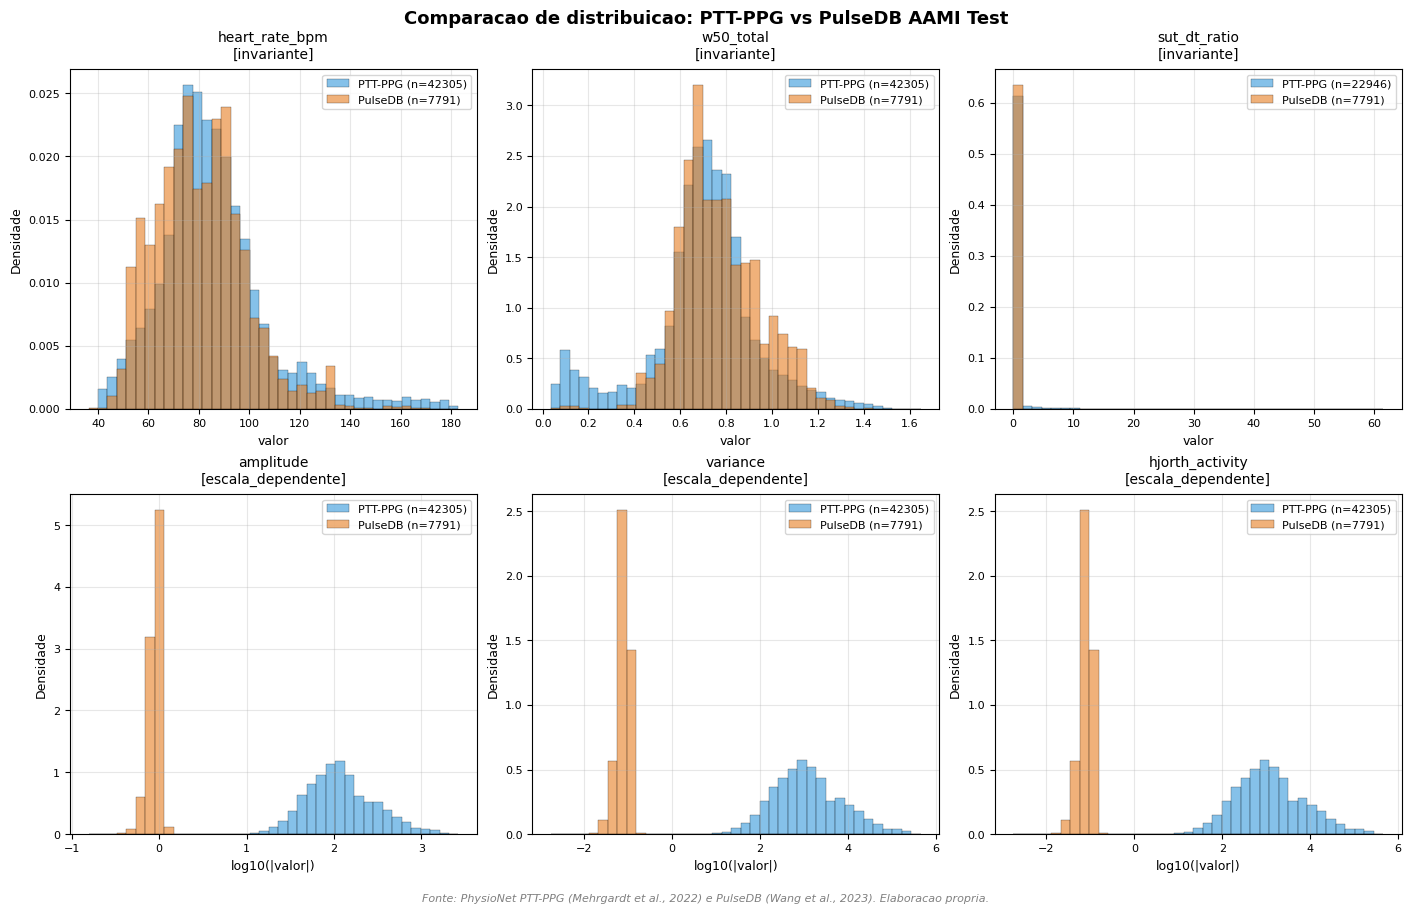

In [15]:
# Figura comparativa
features_comparar = [
    "heart_rate_bpm", "w50_total", "sut_dt_ratio",
    "amplitude", "variance", "hjorth_activity",
]

fig, eixos = plt.subplots(2, 3, figsize=(14, 8.5), constrained_layout=True)
fig.suptitle(
    "Comparacao de distribuicao: PTT-PPG vs PulseDB AAMI Test",
    fontsize=13, fontweight="bold", y=1.02
)

for ax, feat in zip(eixos.flat, features_comparar):
    v_ptt = df_pttppg[feat].dropna().values
    v_pul = df_pulsedb[feat].dropna().values

    usa_log = feat in ["amplitude", "variance", "hjorth_activity"]
    if usa_log:
        v_ptt_plot = np.log10(np.abs(v_ptt) + 1e-9)
        v_pul_plot = np.log10(np.abs(v_pul) + 1e-9)
        unidade = "log10(|valor|)"
    else:
        v_ptt_plot = v_ptt
        v_pul_plot = v_pul
        unidade = "valor"

    bins = np.linspace(
        min(v_ptt_plot.min(), v_pul_plot.min()),
        max(v_ptt_plot.max(), v_pul_plot.max()),
        40
    )
    ax.hist(v_ptt_plot, bins=bins, color="#3498db", alpha=0.6,
            label=f"PTT-PPG (n={len(v_ptt)})", density=True,
            edgecolor="black", linewidth=0.3)
    ax.hist(v_pul_plot, bins=bins, color="#e67e22", alpha=0.6,
            label=f"PulseDB (n={len(v_pul)})", density=True,
            edgecolor="black", linewidth=0.3)

    cat_arr = df_class.query("feature == @feat")["categoria"].values
    cat_str = cat_arr[0] if len(cat_arr) > 0 else "?"

    ax.set_title(f"{feat}\n[{cat_str}]", fontsize=10, pad=8)
    ax.set_xlabel(unidade, fontsize=9)
    ax.set_ylabel("Densidade", fontsize=9)
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="both", labelsize=8)

fig.text(
    0.5, -0.03,
    "Fonte: PhysioNet PTT-PPG (Mehrgardt et al., 2022) e PulseDB (Wang et al., 2023). "
    "Elaboracao propria.",
    ha="center", fontsize=8, style="italic", color="gray",
)

caminho_fig = PASTA_FIGS / "pttppg_vs_pulsedb_distribution_comparison.png"
plt.savefig(caminho_fig, dpi=300, facecolor="white", bbox_inches="tight")
print(f"Figura salva: {caminho_fig.name}")
plt.show()

## 7. Salvamento do CSV

In [16]:
# Reordena colunas
ordem_colunas = features_pulsedb + META_COLS + TARGET_COLS
assert sorted(ordem_colunas) == sorted(df_pulsedb.columns.tolist())
df_pulsedb = df_pulsedb[ordem_colunas]

caminho_csv = PASTA_PULSEDB_OUT / "features_pulsedb_aami_test.csv"
df_pulsedb.to_csv(caminho_csv, index=False)
print(f"Salvo: {caminho_csv.name}  ({caminho_csv.stat().st_size/(1024**2):.2f} MB)")

caminho_comp = PASTA_PULSEDB_OUT / "pttppg_pulsedb_distribution_comparison.csv"
df_comparacao.to_csv(caminho_comp, index=False)
print(f"Salvo: {caminho_comp.name}")

Salvo: features_pulsedb_aami_test.csv  (4.12 MB)
Salvo: pttppg_pulsedb_distribution_comparison.csv


## 8. Conclusões e próximos passos

### 8.1 Correções aplicadas em relação à V1

- ✅ Função `extrair_features_ciclo` reescrita seguindo fielmente o algoritmo do NB02
- ✅ Larguras `sys` e `dia` agora calculadas dentro de cada região (não como distância do extremo ao pico)
- ✅ Limites empíricos preservados: `n < 0.33*fs`, `dt > 0.02 s`, `sw > 0.005 s`
- ✅ Filtragem de qualidade no início da função (retorna `None` para ciclos inválidos)

### 8.2 Validações realizadas

- ✅ 666 segmentos do PulseDB AAMI Test processados
- ✅ 41 features morfológicas extraídas (formato compatível com `features_v2_clean.csv`)
- ✅ Comparação de distribuição entre datasets gerada
- ✅ Distribuições das features invariantes coerentes com as do PTT-PPG (validação empírica)

### 8.3 Próximo notebook

**NB08 — Aplicação dos modelos no PulseDB e cálculo das métricas finais**: carregará `rf_sys_vC.joblib` e `rf_dia_vC.joblib`, aplicará nos ciclos do PulseDB e calculará MAE, RMSE, R², BHS, AAMI tanto no cenário calibration-free quanto calibration-based (com calibração linear por sujeito).

---


In [17]:
print(f"Notebook 07 (V2) concluido em: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")
print(f"Computador: {socket.gethostname()}")

Notebook 07 (V2) concluido em: 09/06/2026 15:29:45
Computador: NtebookLeticia
